In [1]:
import numpy as np
import time
from scipy.io import savemat

# -----------------------------
# Parameters
# -----------------------------
nsx = 32      # number of cells along x
nsy = 32      # number of cells along y
nbz = 16      # number of cells along z
nx = nsx      # number of observation points along x
ny = nsy      # number of observation points along y

len_ = 50.0   # cell size (m)
z_obs = -0.1  # observation height (m)
UGC = 6.67e-11  # gravitational constant (m^3 # Initialize loss trackers

# -----------------------------
# Grid definition
# -----------------------------
Xrange = [len_ / 2.0, nsx * len_ - len_ / 2.0]
Yrange = [len_ / 2.0, nsy * len_ - len_ / 2.0]

Xsrange = [0.0, nsx * len_]
Ysrange = [0.0, nsy * len_]
Zsrange = [0.0, nbz * len_]

# observation points (at centers of surface cells)
Xobserved = np.linspace(Xrange[0], Xrange[1], nx)
Yobserved = np.linspace(Yrange[0], Yrange[1], ny)

# cell boundaries
position_nsx = np.linspace(Xsrange[0], Xsrange[1], nsx + 1)
position_nsy = np.linspace(Ysrange[0], Ysrange[1], nsy + 1)
position_nbz = np.linspace(Zsrange[0], Zsrange[1], nbz + 1)

# -----------------------------
# Initialize Txx matrix
# -----------------------------
# rows: nx*ny obs, cols: nsx*nsy*nbz cells
Txx = np.zeros((nx * ny, nsx * nsy * nbz), dtype=float)

# -----------------------------
# Compute Txx
# -----------------------------
start = time.time()
eps = 1e-12  # to avoid log(0) and division by zero

for i1 in range(nx):
    for i2 in range(ny):

        x_obs = Xobserved[i1]
        y_obs = Yobserved[i2]

        for j1 in range(nsx):
            for j2 in range(nsy):
                for j3 in range(nbz):

                    # cell boundaries
                    x1 = position_nsx[j1]
                    x2 = position_nsx[j1 + 1]

                    y1 = position_nsy[j2]
                    y2 = position_nsy[j2 + 1]

                    z1 = position_nbz[j3]
                    z2 = position_nbz[j3 + 1]

                    # accumulate contribution of this cell to Gx at this obs
                    val = 0.0

                    # loop over 8 corners (l,m,n = 0 or 1)
                    for l in range(2):
                        xl = x1 if l == 0 else x2
                        dx = x_obs - xl  # X - xl

                        for m in range(2):
                            ym = y1 if m == 0 else y2
                            dy = y_obs - ym  # Y - ym

                            for n in range(2):
                                zn = z1 if n == 0 else z2
                                dz = z_obs - zn  # Z - zn

                                r = np.sqrt(dx**2 + dy**2 + dz**2) 

                                s = (-1)**(l + m + n)
                                #r[r == 0] = 1e-10  # Avoid division by zero
                                denominator = dx* r
                                safe_denominator = np.where(denominator == 0, 1e-10, denominator)
                                val +=s * np.arctan(((dy) * (dz)) / safe_denominator)

                    # flatten indices
                    index1 = i1 + nx * i2
                    index2 = j1 + nsx * j2 + nsx * nsy * j3

                    # kernel value for txx (per unit density), convert to E/(kg/m3)
                    Txx[index1, index2] = -UGC * val * 1e9

end = time.time()
print(f"Computation finished in {end - start:.2f} seconds")

# -----------------------------
# Save Txx matrix to .mat file
# -----------------------------
savemat('Txx_matrix.mat', {'Txx': Txx})
print("✅ Txx kernel matrix saved as 'Txx_matrix.mat'")


Computation finished in 1057.67 seconds
✅ Txx kernel matrix saved as 'Txx_matrix.mat'


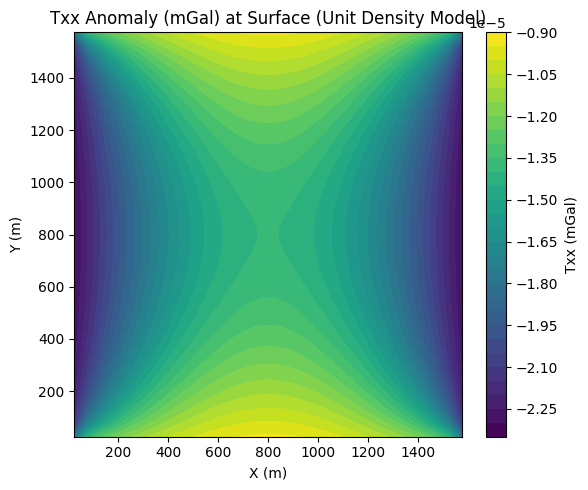

In [2]:
# -----------------------------
import matplotlib.pyplot as plt

# Here we assume density = 1 kg/m^3 in all cells
density_model = np.ones(nsx * nsy * nbz, dtype=float)
#rho = 2.7

# Txx data (mGal) at all observation points
Txx_data = Txx@density_model   # shape: (nx*ny,)

# reshape to 2D grid (ny, nx) for contour plotting
Txx_grid = Txx_data.reshape(ny, nx)

# create meshgrid for plotting
Xgrid, Ygrid = np.meshgrid(Xobserved, Yobserved)

# -----------------------------
# Plot contour map of Txx
# -----------------------------
plt.figure(figsize=(6, 5))
contour = plt.contourf(Xgrid, Ygrid, Txx_grid, levels=30)
plt.xlabel('X (m)')
plt.ylabel('Y (m)')
plt.title('Txx Anomaly (mGal) at Surface (Unit Density Model)')
cbar = plt.colorbar(contour)
cbar.set_label('Txx (mGal)')
plt.tight_layout()
plt.show()
